In [1]:
# =============================================================================
# CELL 1 - Configuration
# Every tunable setting lives here. Change values here, not inside later cells.
# =============================================================================
from types import SimpleNamespace

CFG = SimpleNamespace(
    # --- Data ---
    input_root   = r"X:\aanand37\Manuscript\Snapshot Wisconsin\data",
    csv_name     = "Snapshot_WI-Oh_Deer_data-v1.csv",
    photos_sub   = os.path.join("Snapshot_WI-Oh_Deer_Photos", "Deer") if "os" in dir() else r"Snapshot_WI-Oh_Deer_Photos\Deer",
    # Column that groups near-duplicate images (e.g. camera site, burst/sequence id).
    # All images in a group go to the same split so they can't leak between train and test.
    # None = group by image file only (prevents multi-deer rows of one photo from being split).
    group_col    = None,

    # --- Preprocessing ---
    img_size     = 256,
    use_bbox     = True,          # crop to the deer using the CSV's bounding box
    bbox_pad     = 0.15,          # enlarge the box by 15% on each side before cropping

    # --- Model ---
    model_name   = "efficientnet_b0", #"efficientnet_b0",   # any timm model, e.g. "convnext_nano"
    dropout      = 0.3,

    # --- Optimisation ---
    epochs       = 50,            # maximum; early stopping usually ends sooner
    batch_size   = 32,
    lr           = 3e-4,          # peak learning rate (reached after warmup)
    weight_decay = 1e-4,
    warmup_epochs = 1,            # linear LR warmup from ~0 to lr
    label_smooth = 0.05,
    grad_clip    = 1.0,           # max gradient norm; None to disable
    amp          = True,          # mixed precision

    # --- LR reduction on plateau (after warmup) ---
    plateau_factor   = 0.3,       # multiply LR by this when val F1 stalls
    plateau_patience = 2,         # epochs without improvement before reducing LR
    min_lr           = 1e-6,

    # --- Early stopping ---
    patience     = 5,             # epochs without improvement before stopping (> plateau_patience,
                                  # so LR gets reduced at least twice before we give up)
    min_delta    = 1e-3,          # smallest val macro-F1 gain that counts as improvement

    # --- Splits ---
    val_frac     = 0.15,          # used for early stopping, LR schedule, threshold tuning
    test_frac    = 0.15,          # touched once, at the very end
    seed         = 42,

    # --- Runtime ---
    num_workers  = 2,             # forced to 0 on Windows (see Cell 2)
    log_every    = 1,             # print every N training batches (1 = every batch)
    tune_threshold = True,        # pick decision threshold on val to maximise macro-F1
    
    # --- Output ---
    out_dir      = r"X:\aanand37\Manuscript\Snapshot Wisconsin\data",
    model_file   = "antler_model.pt",
    pred_file    = "antler_test_predictions.csv",
)
print(CFG)

namespace(input_root='X:\\aanand37\\Manuscript\\Snapshot Wisconsin\\data', csv_name='Snapshot_WI-Oh_Deer_data-v1.csv', photos_sub='Snapshot_WI-Oh_Deer_Photos\\Deer', group_col=None, img_size=256, use_bbox=True, bbox_pad=0.15, model_name='efficientnet_b0', dropout=0.3, epochs=50, batch_size=32, lr=0.0003, weight_decay=0.0001, warmup_epochs=1, label_smooth=0.05, grad_clip=1.0, amp=True, plateau_factor=0.3, plateau_patience=2, min_lr=1e-06, patience=5, min_delta=0.001, val_frac=0.15, test_frac=0.15, seed=42, num_workers=2, log_every=1, tune_threshold=True, out_dir='X:\\aanand37\\Manuscript\\Snapshot Wisconsin\\data', model_file='antler_model.pt', pred_file='antler_test_predictions.csv')


In [2]:
# =============================================================================
# CELL 2 - Imports, reproducibility, GPU check
# =============================================================================
import sys, subprocess

def _pip(pkg):
    """Install a package into THIS kernel's Python, only if it's missing."""
    try:
        __import__(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

_pip("timm")

import os, re, glob, random, time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
Image.MAX_IMAGE_PIXELS = None   # camera-trap JPEGs can be large; disable PIL's size guard

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm
import sklearn
from sklearn.model_selection import train_test_split   # (StratifiedGroupKFold needs sklearn >= 1.0)
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report

def seed_everything(seed):
    """Seed Python, NumPy and PyTorch RNGs so splits and initialisation are repeatable."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(CFG.seed)

if not torch.cuda.is_available():
    raise RuntimeError(
        f"GPU required but CUDA is unavailable. Python: {sys.executable}; "
        f"torch {torch.__version__}; compiled CUDA: {torch.version.cuda}"
    )
torch.cuda.set_device(0)
DEVICE = "cuda"
torch.backends.cudnn.benchmark = True   # fixed input size -> cuDNN picks the fastest kernels

# In Jupyter on Windows, DataLoader worker processes can't import classes defined in the
# notebook and hang. Loading in the main process is slower but reliable.
if os.name == "nt":
    CFG.num_workers = 0

print(f"torch {torch.__version__} | timm {timm.__version__} | sklearn {sklearn.__version__} | "
      f"pandas {pd.__version__} | numpy {np.__version__}")
print(f"GPU: {torch.cuda.get_device_name(1)} | DataLoader workers: {CFG.num_workers} | AMP: {CFG.amp}") ## Change GPU name

C:\ProgramData\Anaconda3\lib\site-packages\scipy\__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.24.2
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


torch 2.3.0+cu118 | timm 1.0.13 | sklearn 0.24.2 | pandas 2.0.3 | numpy 1.24.2
GPU: NVIDIA A100-PCIE-40GB | DataLoader workers: 0 | AMP: True



# 3. Load data & auto-detect the schema
The dataset is one CSV (a row per image, 10 columns, including a bounding box) plus a folder of ~4,880 JPGs.

Because a real-world CSV rarely has exactly the column names you expect, the cell below auto-detects which columns hold the filename, the Antlers label, the Age label, and the bounding box — by fuzzy keyword matching. It prints what it found so you can sanity-check. If it guesses wrong, override the COLS dict manually.

In [3]:
# =============================================================================
# CELL 3 - Locate and load the data
# =============================================================================
CFG.csv_path   = os.path.join(CFG.input_root, CFG.csv_name)
CFG.photos_dir = os.path.join(CFG.input_root, "Snapshot_WI-Oh_Deer_Photos", "Deer")

if not os.path.isfile(CFG.csv_path):
    raise FileNotFoundError(f"CSV not found: {CFG.csv_path}")
if not os.path.isdir(CFG.photos_dir):
    raise FileNotFoundError(f"Photo folder not found: {CFG.photos_dir}")

n_jpgs = len(glob.glob(os.path.join(CFG.photos_dir, "*.jpg")))
print(f"CSV      : {CFG.csv_path}")
print(f"Photos   : {CFG.photos_dir} ({n_jpgs} .jpg files)")

df = pd.read_csv(CFG.csv_path)
print(f"CSV shape: {df.shape}")
print(f"Columns  : {list(df.columns)}")
print(df.head())

CSV      : X:\aanand37\Manuscript\Snapshot Wisconsin\data\Snapshot_WI-Oh_Deer_data-v1.csv
Photos   : X:\aanand37\Manuscript\Snapshot Wisconsin\data\Snapshot_WI-Oh_Deer_Photos\Deer (4880 .jpg files)
CSV shape: (4880, 10)
Columns  : ['filename', 'year', 'month', 'bbox_origin_x', 'bbox_origin_y', 'bbox_width', 'bbox_height', 'bbox_confidence', 'antler_status', 'age_status']
                   filename  year  month  bbox_origin_x  bbox_origin_y  \
0  SSWI000000027884533B.jpg  2022      6         0.2687         0.1066   
1  SSWI000000019469717A.jpg  2020      9         0.4831         0.2608   
2  SSWI000000020749648B.jpg  2021      1         0.0000         0.4750   
3  SSWI000000010695719B.jpg  2018      8         0.2587         0.4591   
4  SSWI000000020110273C.jpg  2020      8         0.2068         0.7733   

   bbox_width  bbox_height  bbox_confidence antler_status age_status  
0      0.5043       0.6933            0.966    ANTLERLESS      YOUNG  
1      0.5168       0.7275            0

In [4]:
# =============================================================================
# CELL 4 - Detect the columns we need
# =============================================================================
def find_col(df, keywords, exclude=()):
    """Return the column that best matches the EARLIEST keyword in `keywords`.

    - Keywords of <= 2 characters (e.g. 'x', 'w', 'h') must match a whole token of the
      column name, so 'h' does NOT match inside 'width'.
    - Longer keywords match as substrings.
    - Columns containing any string in `exclude` are skipped.
    Returns None if nothing matches.
    """
    def tokens(c):
        return {t for t in re.split(r"[^a-z0-9]+", c.lower()) if t}

    best, best_rank = None, float("inf")
    for c in df.columns:
        lc = c.lower()
        if any(x in lc for x in exclude):
            continue
        toks = tokens(c)
        for rank, k in enumerate(keywords):
            hit = (k in toks) if len(k) <= 2 else (k in lc)
            if hit:
                if rank < best_rank:
                    best, best_rank = c, rank
                break
    return best

COLS = {
    "image":  find_col(df, ["filename", "file", "image", "photo", "img", "name"],
                       exclude=["width", "height", "size"]),
    "antler": find_col(df, ["antler"]),
    # Bounding box: supports (x, y, w, h) and (xmin, ymin, xmax, ymax).
    # 'image'/'img' are excluded so image-dimension columns aren't taken as box size.
    "x":    find_col(df, ["xmin", "x_min", "left", "bbox_x", "x"], exclude=["max", "image", "img"]),
    "y":    find_col(df, ["ymin", "y_min", "top", "bbox_y", "y"],  exclude=["max", "image", "img"]),
    "w":    find_col(df, ["bbox_w", "width", "w"],  exclude=["image", "img"]),
    "h":    find_col(df, ["bbox_h", "height", "h"], exclude=["image", "img"]),
    "xmax": find_col(df, ["xmax", "x_max", "right"]),
    "ymax": find_col(df, ["ymax", "y_max", "bottom"]),
}

print("Detected columns:")
for k, v in COLS.items():
    print(f"  {k:7s} -> {v}")

for required in ("image", "antler"):
    if COLS[required] is None:
        raise KeyError(f"Could not detect the '{required}' column. Set COLS['{required}'] manually.")

print("\nCheck the mapping above. Override if wrong, e.g.  COLS['antler'] = 'AntlerStatus'")

Detected columns:
  image   -> filename
  antler  -> antler_status
  x       -> bbox_origin_x
  y       -> bbox_origin_y
  w       -> bbox_width
  h       -> bbox_height
  xmax    -> None
  ymax    -> None

Check the mapping above. Override if wrong, e.g.  COLS['antler'] = 'AntlerStatus'


In [5]:
# =============================================================================
# CELL 5 - Labels and image-file check -> `data` (the usable rows)
# =============================================================================
ANTLER_NAMES = ["Antlerless", "Antlered"]   # class index 0, class index 1

# Short codes must match the WHOLE value (so "10" is not read as "1").
# Words may appear anywhere in the value ("antlered buck" -> positive).
POS_EXACT = {"1", "1.0", "yes", "y", "true"}
NEG_EXACT = {"0", "0.0", "no", "n", "false"}
POS_WORDS = ["antlered", "buck"]
NEG_WORDS = ["antlerless", "doe"]

def normalize_label(series):
    """Map raw antler values to 1.0 (antlered), 0.0 (antlerless) or NaN (unknown / conflicting)."""
    def map_one(v):
        pos = v in POS_EXACT or any(w in v for w in POS_WORDS)
        neg = v in NEG_EXACT or any(w in v for w in NEG_WORDS)
        if pos and not neg:
            return 1.0
        if neg and not pos:
            return 0.0
        return np.nan                      # no match, or matched both lists
    return series.astype(str).str.strip().str.lower().map(map_one)

df["y_antler"] = normalize_label(df[COLS["antler"]])

# Show exactly how every raw value was mapped - VERIFY THIS before training.
raw = df[COLS["antler"]].astype(str).str.strip().str.lower()
mapped = df["y_antler"].map({1.0: "1 (Antlered)", 0.0: "0 (Antlerless)"}).fillna("NaN (dropped)")
print("Raw value -> mapped label:")
print(pd.DataFrame({"raw": raw, "mapped": mapped})
        .groupby(["raw", "mapped"]).size().rename("n")
        .sort_values(ascending=False).reset_index().to_string(index=False))

# Resolve image paths and check each file exists. A missing file must be dropped here,
# never replaced by a placeholder image during training.
def resolve(fn):
    fn = str(fn).strip()
    return fn if os.path.isabs(fn) else os.path.join(CFG.photos_dir, fn)

df["path"] = df[COLS["image"]].map(resolve)
df["file_exists"] = df["path"].map(os.path.isfile)

n_missing = int((~df["file_exists"]).sum())
if df["file_exists"].sum() == 0:
    raise FileNotFoundError(f"No image files found. Example path tried: {df['path'].iloc[0]}")
if n_missing:
    print(f"\n{n_missing} rows point to missing image files and will be dropped. Examples:")
    print(df.loc[~df["file_exists"], "path"].head().to_string(index=False))

data = df[df["y_antler"].notna() & df["file_exists"]].reset_index(drop=True).copy()
data["y_antler"] = data["y_antler"].astype(int)

print(f"\nUsable rows: {len(data)} of {len(df)} "
      f"({int(df['y_antler'].isna().sum())} unmapped labels, {n_missing} missing files)")
print(f"Unique image files: {data['path'].nunique()}")
print("Class counts:", {ANTLER_NAMES[k]: int(v) for k, v in data["y_antler"].value_counts().sort_index().items()})

Raw value -> mapped label:
       raw         mapped    n
antlerless 0 (Antlerless) 3416
  antlered   1 (Antlered) 1464

Usable rows: 4880 of 4880 (0 unmapped labels, 0 missing files)
Unique image files: 4880
Class counts: {'Antlerless': 3416, 'Antlered': 1464}


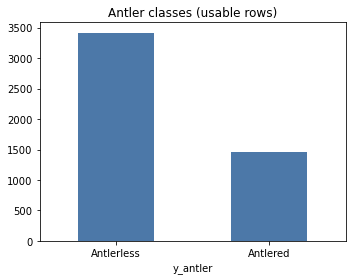

Estimated night (IR) fraction in a 200-image sample: 57%


In [6]:
# =============================================================================
# CELL 6 - Quick look: class balance and day/night mix
# =============================================================================
fig, ax = plt.subplots(figsize=(5, 4))
(data["y_antler"].map(dict(enumerate(ANTLER_NAMES)))
     .value_counts().reindex(ANTLER_NAMES)
     .plot.bar(ax=ax, color="#4C78A8", title="Antler classes (usable rows)"))
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

def is_night(path, thresh=12):
    """True if the image looks like an IR night shot (near-zero colour saturation).
    Returns None if the file can't be read."""
    try:
        with Image.open(path) as im:
            arr = np.asarray(im.convert("RGB").resize((64, 64)), dtype=np.float32)
        return bool((arr.max(-1) - arr.min(-1)).mean() < thresh)
    except Exception:
        return None

sample = data["path"].sample(min(200, len(data)), random_state=0)
flags = [f for f in (is_night(p) for p in sample) if f is not None]   # skip unreadable files
if flags:
    print(f"Estimated night (IR) fraction in a {len(flags)}-image sample: {np.mean(flags):.0%}")
else:
    print("No readable images in the sample.")

# 4. Exploratory data analysis
Two things drive the modelling choices here:

Class balance. F1 (not accuracy) is the metric precisely because these tags are imbalanced — most deer are Adult and, depending on season, most are Antlerless. A model that always predicts the majority class gets high accuracy but terrible F1. We'll counter this with class-weighted loss and threshold tuning.
Bounding-box coverage. Antlers are a fine detail. Cropping to the deer (using the provided box) removes distracting background and makes the antler signal far easier to learn.

# 5. Dataset, bounding-box cropping & augmentation
The DeerDataset reads an image, optionally crops to the deer using the bounding box (expanded by bbox_pad so we don't clip antlers), and applies augmentation. Both bbox conventions — (x, y, w, h) and (xmin, ymin, xmax, ymax) — and both normalized (0–1) and pixel coordinates are handled.

Augmentation is deliberately mild and label-preserving: horizontal flip (a flipped buck is still a buck), small rotation/scale/color jitter to simulate different cameras, lighting, and seasons.

In [7]:
# =============================================================================
# CELL 7 - Image loading (tolerates damaged JPEGs), bbox cropping, Dataset
# =============================================================================
from PIL import ImageFile

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

def get_bbox(row, W, H):
    """Return (left, top, right, bottom) in pixels of the ORIGINAL image, or None."""
    c = COLS
    try:
        if c["x"] and c["y"] and c["xmax"] and c["ymax"]:            # corner format
            l, t, r, b = (float(row[c[k]]) for k in ("x", "y", "xmax", "ymax"))
        elif c["x"] and c["y"] and c["w"] and c["h"]:                  # x, y, width, height
            x, y, w, h = (float(row[c[k]]) for k in ("x", "y", "w", "h"))
            l, t, r, b = x, y, x + w, y + h
        else:
            return None
    except (ValueError, TypeError, KeyError):
        return None
    if not np.all(np.isfinite([l, t, r, b])):                          # NaN / inf box
        return None
    if max(l, t, r, b) <= 1.5:                                          # normalised 0-1 coords
        l, r, t, b = l * W, r * W, t * H, b * H
    if not (r > l and b > t):
        return None
    return l, t, r, b

def crop_to_bbox(img, box, pad):
    """Crop `img` to `box` enlarged by `pad` (fraction of box size), clipped to the image."""
    W, H = img.size
    l, t, r, b = box
    pw, ph = (r - l) * pad, (b - t) * pad
    l, t = max(0, l - pw), max(0, t - ph)
    r, b = min(W, r + pw), min(H, b + ph)
    return img.crop((int(l), int(t), int(r), int(b)))

def load_rgb(path):
    """Open an image as RGB in STRICT mode: a damaged JPEG raises instead of being
    silently filled with grey. Cell 7b should already have removed all of them."""
    ImageFile.LOAD_TRUNCATED_IMAGES = False
    with Image.open(path) as im:
        return im.convert("RGB")

class DeerDataset(Dataset):
    """Yields (image_tensor, label) for one label column (default: antler)."""

    def __init__(self, frame, label_col="y_antler", train=False):
        self.df = frame.reset_index(drop=True)      # positional indexing below relies on this
        self.label_col = label_col
        if train:
            aug = [
                T.RandomResizedCrop(CFG.img_size, scale=(0.75, 1.0), ratio=(0.8, 1.25)),
                T.RandomHorizontalFlip(),
                T.RandomRotation(8),
                T.ColorJitter(0.2, 0.2, 0.2, 0.02),
            ]
        else:
            aug = [T.Resize((CFG.img_size, CFG.img_size))]
        self.tf = T.Compose(aug + [T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        try:
            img = load_rgb(row["path"])
        except Exception as e:
            # Should not happen after Cell 7b; if it does, the file changed after the scan.
            raise RuntimeError(f"Could not read image: {row['path']}") from e
        if CFG.use_bbox:
            box = get_bbox(row, *img.size)
            if box is not None:
                img = crop_to_bbox(img, box, CFG.bbox_pad)
        x = self.tf(img)
        y = torch.tensor(int(row[self.label_col]), dtype=torch.long)
        return x, y

In [ ]:
## 

In [11]:
# =============================================================================
# CELL 7b - Find damaged / unreadable JPEGs and DROP them
# Every image is fully decoded once in strict mode; any decode error = damaged.
# Results are cached and a file is re-scanned only if its size or modified time changes
# (e.g. after you re-copy it from the source).
# =============================================================================
from PIL import ImageFile

def image_is_ok(path):
    """True if the file decodes completely without error, False if damaged or unreadable."""
    ImageFile.LOAD_TRUNCATED_IMAGES = False          # strict: any truncation/corruption raises
    try:
        with Image.open(path) as im:
            im.load()                                # forces a full decode (open() alone doesn't)
        return True
    except Exception:
        return False

# ---- Load cache, scan only new/changed files ----
cache_path = os.path.join(CFG.out_dir, "image_integrity.csv")
paths = pd.Series(data["path"].unique(), name="path")
stat = pd.DataFrame({"path": paths,
                     "size": paths.map(os.path.getsize),
                     "mtime": paths.map(lambda p: int(os.path.getmtime(p)))})

if os.path.isfile(cache_path):
    cached = pd.read_csv(cache_path)[["path", "size", "mtime", "ok"]]
    integrity = stat.merge(cached, on=["path", "size", "mtime"], how="left")
else:
    integrity = stat.assign(ok=np.nan)

todo = integrity.index[integrity["ok"].isna()]
print(f"Integrity scan: {len(todo)} of {len(integrity)} files need scanning "
      f"({len(integrity) - len(todo)} cached)")
t0 = time.time()
for n, idx in enumerate(todo, 1):
    integrity.at[idx, "ok"] = image_is_ok(integrity.at[idx, "path"])
    if n % 250 == 0 or n == len(todo):
        print(f"  scanned {n}/{len(todo)}  ({time.time()-t0:.0f}s)", flush=True)

integrity["ok"] = integrity["ok"].astype(bool)
os.makedirs(CFG.out_dir, exist_ok=True)
integrity.to_csv(cache_path, index=False)

# ---- Drop rows whose image file is damaged ----
bad_paths = set(integrity.loc[~integrity["ok"], "path"])
drop = data["path"].isin(bad_paths)

print(f"\n{len(bad_paths)} damaged image files -> dropping {int(drop.sum())} rows")
if drop.any():
    dropped = data.loc[drop, [COLS["image"], "path", "y_antler"]]
    print(dropped[[COLS["image"], "y_antler"]].to_string(index=False))
    # Keep a record of what was excluded (useful for the methods section).
    dropped.to_csv(os.path.join(CFG.out_dir, "dropped_damaged_images.csv"), index=False)

data = data[~drop].reset_index(drop=True)
print(f"\nUsable rows now: {len(data)}")
print("Class counts:", {ANTLER_NAMES[k]: int(v)
                        for k, v in data["y_antler"].value_counts().sort_index().items()})

Integrity scan: 0 of 4879 files need scanning (4879 cached)

0 damaged image files -> dropping 0 rows

Usable rows now: 4879
Class counts: {'Antlerless': 3415, 'Antlered': 1464}


In [12]:
# =============================================================================
# CELL 8 - Model, evaluation, training loop (warmup + LR-on-plateau + early stopping)
# =============================================================================
class AntlerNet(nn.Module):
    """Pretrained timm backbone + dropout + one linear head (2 classes)."""

    def __init__(self, backbone=None, n_classes=2, drop=None):
        super().__init__()
        # CFG is read when the model is BUILT (not when the class is defined),
        # so changing CFG.model_name / CFG.dropout later takes effect.
        backbone = backbone or CFG.model_name
        drop = CFG.dropout if drop is None else drop
        self.backbone = timm.create_model(backbone, pretrained=True, num_classes=0, global_pool="avg")
        self.drop = nn.Dropout(drop)
        self.head = nn.Linear(self.backbone.num_features, n_classes)

    def forward(self, x):
        return self.head(self.drop(self.backbone(x)))

def make_loader(frame, train):
    """Training loader shuffles and drops the last partial batch; eval loader keeps row order."""
    return DataLoader(
        DeerDataset(frame, train=train),
        batch_size=CFG.batch_size if train else CFG.batch_size * 2,
        shuffle=train,
        drop_last=train,
        num_workers=CFG.num_workers,
        pin_memory=True,
    )

def make_grad_scaler():
    """AMP gradient scaler that works on both new and old PyTorch."""
    try:
        return torch.amp.GradScaler("cuda", enabled=CFG.amp)     # torch >= 2.3
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=CFG.amp)       # older torch

def class_weights(y):
    """Inverse-frequency weights so the rarer class counts as much as the common one."""
    vals, counts = np.unique(y, return_counts=True)
    w = torch.ones(2)
    for v, c in zip(vals, counts):
        w[int(v)] = counts.sum() / (len(vals) * c)
    return w.float().to(DEVICE)

@torch.no_grad()
def evaluate(model, dl, criterion=None, threshold=0.5):
    """Run the model over `dl`.

    Returns loss, macro-F1, accuracy and confusion matrix at `threshold`,
    plus raw P(antlered) and the true labels, both in loader order.
    """
    model.eval()
    probs, labels, loss_sum, n = [], [], 0.0, 0
    for x, y in dl:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        with torch.autocast("cuda", enabled=CFG.amp):
            logits = model(x)
        logits = logits.float()                      # compute loss/softmax in full precision
        if criterion is not None:
            loss_sum += criterion(logits, y).item() * len(y)
        n += len(y)
        probs.append(logits.softmax(1)[:, 1].cpu().numpy())
        labels.append(y.cpu().numpy())
    probs = np.concatenate(probs)
    labels = np.concatenate(labels).astype(int)
    preds = (probs > threshold).astype(int)
    return {
        "loss":  loss_sum / n if criterion is not None else float("nan"),
        "f1":    f1_score(labels, preds, average="macro", zero_division=0),
        "acc":   accuracy_score(labels, preds),
        "cm":    confusion_matrix(labels, preds, labels=[0, 1]),
        "probs": probs,
        "labels": labels,
    }

def train_antler(tr, va, ckpt_path, tag="antler"):
    """Train on `tr`, monitor `va`. Returns (best model, per-epoch history DataFrame).

    Schedule:
      1. Linear LR warmup to CFG.lr over CFG.warmup_epochs.
      2. ReduceLROnPlateau: LR *= plateau_factor when val macro-F1 stalls.
      3. Early stopping after CFG.patience epochs without a gain > CFG.min_delta.
    The best-F1 weights are kept in memory AND saved to `ckpt_path` on every improvement,
    so a crash or kernel restart doesn't lose them.
    """
    dl_tr = make_loader(tr, train=True)
    dl_va = make_loader(va, train=False)
    if len(dl_tr) == 0 or len(dl_va) == 0:
        raise ValueError("Empty loader - reduce batch_size.")

    model = AntlerNet().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay)
    plateau = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="max", factor=CFG.plateau_factor, patience=CFG.plateau_patience,
        threshold=CFG.min_delta, threshold_mode="abs", min_lr=CFG.min_lr,
    )
    scaler = make_grad_scaler()
    w = class_weights(tr["y_antler"].values)
    criterion = nn.CrossEntropyLoss(weight=w, label_smoothing=CFG.label_smooth)

    warmup_steps = CFG.warmup_epochs * len(dl_tr)
    max_steps = CFG.epochs * len(dl_tr)

    # ---- Print the setup ----
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f"[{tag}] model {CFG.model_name}: {n_params:.1f}M params on {next(model.parameters()).device}")
    print(f"[{tag}] train {len(tr)} rows -> {len(dl_tr)} batches/epoch | "
          f"val {len(va)} rows -> {len(dl_va)} batches")
    print(f"[{tag}] class weights: {ANTLER_NAMES[0]}={w[0]:.3f}, {ANTLER_NAMES[1]}={w[1]:.3f}")
    print(f"[{tag}] max epochs {CFG.epochs} ({max_steps} steps), warmup {warmup_steps} steps, "
          f"peak lr {CFG.lr:.1e}")
    print(f"[{tag}] LR plateau: x{CFG.plateau_factor} after {CFG.plateau_patience} flat epochs "
          f"(min {CFG.min_lr:.0e})")
    print(f"[{tag}] early stopping: patience {CFG.patience}, min_delta {CFG.min_delta}", flush=True)
    torch.cuda.reset_peak_memory_stats()

    best_f1, best_state, best_ep, bad_epochs, gstep = -1.0, None, -1, 0, 0
    history = []

    for ep in range(CFG.epochs):
        model.train()
        t_ep = t_log = time.time()
        loss_sum, correct, seen = 0.0, 0, 0
        print(f"\n[{tag}] ===== epoch {ep+1}/{CFG.epochs} | lr {opt.param_groups[0]['lr']:.2e} =====",
              flush=True)

        for i, (x, y) in enumerate(dl_tr):
            # Linear warmup: set this step's LR before the optimizer update.
            if gstep < warmup_steps:
                for g in opt.param_groups:
                    g["lr"] = CFG.lr * (gstep + 1) / warmup_steps

            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=CFG.amp):
                logits = model(x)
                loss = criterion(logits, y)
            scaler.scale(loss).backward()
            if CFG.grad_clip:
                scaler.unscale_(opt)                            # clip the true (unscaled) gradients
                nn.utils.clip_grad_norm_(model.parameters(), CFG.grad_clip)
            scaler.step(opt)
            scaler.update()
            gstep += 1

            # ---- Per-step logging ----
            loss_v = loss.item()
            batch_correct = (logits.argmax(1) == y).sum().item()
            loss_sum += loss_v
            correct += batch_correct
            seen += len(y)
            if (i + 1) % CFG.log_every == 0 or i + 1 == len(dl_tr):
                print(f"[{tag}] ep {ep+1:02d} step {i+1:4d}/{len(dl_tr)} (global {gstep})  "
                      f"loss {loss_v:.4f}  avg {loss_sum/(i+1):.4f}  "
                      f"batch acc {batch_correct/len(y):.3f}  lr {opt.param_groups[0]['lr']:.2e}  "
                      f"{time.time()-t_log:.2f}s", flush=True)
                t_log = time.time()

        # ---- End of epoch: validate ----
        v = evaluate(model, dl_va, criterion)
        train_loss, train_acc = loss_sum / len(dl_tr), correct / seen
        print(f"[{tag}] epoch {ep+1:02d} | train loss {train_loss:.4f} acc {train_acc:.4f} | "
              f"val loss {v['loss']:.4f} acc {v['acc']:.4f} macroF1 {v['f1']:.4f} | "
              f"{time.time()-t_ep:.0f}s | peak GPU {torch.cuda.max_memory_allocated()/1024**3:.2f} GiB",
              flush=True)
        print(f"[{tag}] val confusion (rows = actual {ANTLER_NAMES}, cols = predicted):\n{v['cm']}",
              flush=True)
        history.append({"epoch": ep + 1, "lr": opt.param_groups[0]["lr"],
                        "train_loss": train_loss, "train_acc": train_acc,
                        "val_loss": v["loss"], "val_acc": v["acc"], "val_f1": v["f1"]})

        # ---- Keep the best weights (any gain) and save them to disk ----
        significant = v["f1"] > best_f1 + CFG.min_delta
        if v["f1"] > best_f1:
            best_f1, best_ep = v["f1"], ep
            best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}
            torch.save({"state_dict": best_state, "model_name": CFG.model_name,
                        "img_size": CFG.img_size, "label_names": ANTLER_NAMES,
                        "best_epoch": ep + 1, "val_f1": best_f1}, ckpt_path)
            print(f"[{tag}] new best val macroF1 {best_f1:.4f} -> saved {ckpt_path}", flush=True)

        # ---- LR schedule + early stopping (both inactive during warmup) ----
        if ep + 1 <= CFG.warmup_epochs:
            bad_epochs = 0
            continue
        plateau.step(v["f1"])
        if significant:
            bad_epochs = 0
        else:
            bad_epochs += 1
            print(f"[{tag}] no gain > {CFG.min_delta}: {bad_epochs}/{CFG.patience}", flush=True)
            if bad_epochs >= CFG.patience:
                print(f"[{tag}] EARLY STOP at epoch {ep+1}; best epoch {best_ep+1}", flush=True)
                break
    else:
        # Runs only if the loop finished without `break`.
        print(f"[{tag}] reached max epochs ({CFG.epochs}) without early stopping - "
              f"consider raising CFG.epochs.", flush=True)

    model.load_state_dict(best_state)
    print(f"\n[{tag}] restored best weights: epoch {best_ep+1}, val macroF1 {best_f1:.4f}")
    return model, pd.DataFrame(history)

# 6. Training

In [13]:
# =============================================================================
# CELL 9 - Grouped, stratified train / val / test split, then train
# =============================================================================
def _group_split(frame, test_size, seed):
    """Split `frame` in two so every group (column `_group`) lands entirely on one side.

    Stratification is done at the GROUP level using each group's majority antler label,
    so class balance is kept approximately. Sizes are fractions of groups, not rows,
    so they are approximate when groups differ in size.
    """
    group_label = frame.groupby("_group")["y_antler"].mean().round().astype(int)
    groups, labels = group_label.index.values, group_label.values
    try:
        _, g_out = train_test_split(groups, test_size=test_size, random_state=seed, stratify=labels)
    except ValueError:
        # A class has too few groups to stratify (e.g. very few camera sites).
        print("  warning: too few groups per class to stratify; splitting groups randomly")
        _, g_out = train_test_split(groups, test_size=test_size, random_state=seed)
    out_mask = frame["_group"].isin(set(g_out))
    return frame[~out_mask], frame[out_mask]

def split_data(data):
    """Grouped, stratified train / val / test split.

    All rows sharing a group (CFG.group_col, or the image file if None) go to ONE split,
    so multiple deer from one photo - or burst frames, if group_col is set - can't appear
    in both training and evaluation.
    """
    gcol = CFG.group_col or "path"
    d = data.assign(_group=data[gcol].astype(str))

    trval, te = _group_split(d, CFG.test_frac, CFG.seed)                         # ~test_frac
    tr, va = _group_split(trval, CFG.val_frac / (1 - CFG.test_frac), CFG.seed)   # ~val_frac of total

    # Sanity check: no group appears in more than one split.
    s_tr, s_va, s_te = set(tr["_group"]), set(va["_group"]), set(te["_group"])
    assert not (s_tr & s_va or s_tr & s_te or s_va & s_te), "group leak between splits"

    return [x.drop(columns="_group").reset_index(drop=True) for x in (tr, va, te)]

tr, va, te = split_data(data)
print(f"Grouping by: {CFG.group_col or 'image file'}")
for name, d in (("train", tr), ("val", va), ("test", te)):
    counts = d["y_antler"].value_counts().reindex([0, 1], fill_value=0)
    print(f"  {name:5s}: {len(d):5d} rows ({len(d)/len(data):.0%}) | "
          f"{ANTLER_NAMES[0]} {counts[0]}, {ANTLER_NAMES[1]} {counts[1]}")

os.makedirs(CFG.out_dir, exist_ok=True)
ckpt_path = os.path.join(CFG.out_dir, CFG.model_file)

# Save the FULL split rows (incl. bounding-box columns) so evaluation after a kernel
# restart uses exactly the same images and the same cropping.
for name, d in (("train", tr), ("val", va), ("test", te)):
    d.to_csv(os.path.join(CFG.out_dir, f"antler_split_{name}.csv"), index=False)

model, history = train_antler(tr, va, ckpt_path)

print("\nPer-epoch history:")
print(history.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
history.to_csv(os.path.join(CFG.out_dir, "antler_training_history.csv"), index=False)

Grouping by: image file
  train:  3415 rows (70%) | Antlerless 2391, Antlered 1024
  val  :   732 rows (15%) | Antlerless 512, Antlered 220
  test :   732 rows (15%) | Antlerless 512, Antlered 220
[antler] model efficientnet_b0: 4.0M params on cuda:0
[antler] train 3415 rows -> 106 batches/epoch | val 732 rows -> 12 batches
[antler] class weights: Antlerless=0.714, Antlered=1.667
[antler] max epochs 50 (5300 steps), warmup 106 steps, peak lr 3.0e-04
[antler] LR plateau: x0.3 after 2 flat epochs (min 1e-06)
[antler] early stopping: patience 5, min_delta 0.001

[antler] ===== epoch 1/50 | lr 3.00e-04 =====
[antler] ep 01 step    1/106 (global 1)  loss 0.7162  avg 0.7162  batch acc 0.312  lr 2.83e-06  4.96s
[antler] ep 01 step    2/106 (global 2)  loss 0.7576  avg 0.7369  batch acc 0.344  lr 5.66e-06  2.28s
[antler] ep 01 step    3/106 (global 3)  loss 0.6742  avg 0.7160  batch acc 0.438  lr 8.49e-06  1.70s
[antler] ep 01 step    4/106 (global 4)  loss 0.6729  avg 0.7052  batch acc 0.562 

[antler] ep 01 step   75/106 (global 75)  loss 0.5537  avg 0.6470  batch acc 0.719  lr 2.12e-04  1.75s
[antler] ep 01 step   76/106 (global 76)  loss 0.5161  avg 0.6453  batch acc 0.750  lr 2.15e-04  1.77s
[antler] ep 01 step   77/106 (global 77)  loss 0.4654  avg 0.6429  batch acc 0.781  lr 2.18e-04  1.76s
[antler] ep 01 step   78/106 (global 78)  loss 0.5008  avg 0.6411  batch acc 0.719  lr 2.21e-04  1.79s
[antler] ep 01 step   79/106 (global 79)  loss 0.7025  avg 0.6419  batch acc 0.562  lr 2.24e-04  1.72s
[antler] ep 01 step   80/106 (global 80)  loss 0.5147  avg 0.6403  batch acc 0.750  lr 2.26e-04  1.76s
[antler] ep 01 step   81/106 (global 81)  loss 0.3952  avg 0.6373  batch acc 0.875  lr 2.29e-04  1.74s
[antler] ep 01 step   82/106 (global 82)  loss 0.5633  avg 0.6364  batch acc 0.719  lr 2.32e-04  1.76s
[antler] ep 01 step   83/106 (global 83)  loss 0.6609  avg 0.6367  batch acc 0.594  lr 2.35e-04  1.75s
[antler] ep 01 step   84/106 (global 84)  loss 0.4868  avg 0.6349  batch 

[antler] ep 02 step   45/106 (global 151)  loss 0.5241  avg 0.4661  batch acc 0.719  lr 3.00e-04  1.64s
[antler] ep 02 step   46/106 (global 152)  loss 0.4139  avg 0.4650  batch acc 0.844  lr 3.00e-04  1.70s
[antler] ep 02 step   47/106 (global 153)  loss 0.4081  avg 0.4638  batch acc 0.875  lr 3.00e-04  1.64s
[antler] ep 02 step   48/106 (global 154)  loss 0.4889  avg 0.4643  batch acc 0.812  lr 3.00e-04  1.66s
[antler] ep 02 step   49/106 (global 155)  loss 0.5672  avg 0.4664  batch acc 0.656  lr 3.00e-04  1.65s
[antler] ep 02 step   50/106 (global 156)  loss 0.3375  avg 0.4638  batch acc 0.812  lr 3.00e-04  1.71s
[antler] ep 02 step   51/106 (global 157)  loss 0.4531  avg 0.4636  batch acc 0.812  lr 3.00e-04  1.64s
[antler] ep 02 step   52/106 (global 158)  loss 0.3358  avg 0.4612  batch acc 0.875  lr 3.00e-04  1.64s
[antler] ep 02 step   53/106 (global 159)  loss 0.4630  avg 0.4612  batch acc 0.781  lr 3.00e-04  1.69s
[antler] ep 02 step   54/106 (global 160)  loss 0.4258  avg 0.46

[antler] ep 03 step   15/106 (global 227)  loss 0.4635  avg 0.3601  batch acc 0.812  lr 3.00e-04  1.67s
[antler] ep 03 step   16/106 (global 228)  loss 0.4551  avg 0.3661  batch acc 0.750  lr 3.00e-04  1.64s
[antler] ep 03 step   17/106 (global 229)  loss 0.4779  avg 0.3727  batch acc 0.719  lr 3.00e-04  1.61s
[antler] ep 03 step   18/106 (global 230)  loss 0.5649  avg 0.3833  batch acc 0.719  lr 3.00e-04  1.60s
[antler] ep 03 step   19/106 (global 231)  loss 0.3169  avg 0.3798  batch acc 0.781  lr 3.00e-04  1.66s
[antler] ep 03 step   20/106 (global 232)  loss 0.5295  avg 0.3873  batch acc 0.812  lr 3.00e-04  1.64s
[antler] ep 03 step   21/106 (global 233)  loss 0.4391  avg 0.3898  batch acc 0.844  lr 3.00e-04  1.66s
[antler] ep 03 step   22/106 (global 234)  loss 0.3190  avg 0.3866  batch acc 0.906  lr 3.00e-04  1.67s
[antler] ep 03 step   23/106 (global 235)  loss 0.4306  avg 0.3885  batch acc 0.812  lr 3.00e-04  1.62s
[antler] ep 03 step   24/106 (global 236)  loss 0.2946  avg 0.38

[antler] ep 03 step   94/106 (global 306)  loss 0.3291  avg 0.3896  batch acc 0.906  lr 3.00e-04  1.64s
[antler] ep 03 step   95/106 (global 307)  loss 0.2774  avg 0.3884  batch acc 0.938  lr 3.00e-04  1.61s
[antler] ep 03 step   96/106 (global 308)  loss 0.4750  avg 0.3893  batch acc 0.812  lr 3.00e-04  1.67s
[antler] ep 03 step   97/106 (global 309)  loss 0.4059  avg 0.3895  batch acc 0.906  lr 3.00e-04  1.60s
[antler] ep 03 step   98/106 (global 310)  loss 0.3574  avg 0.3892  batch acc 0.906  lr 3.00e-04  1.68s
[antler] ep 03 step   99/106 (global 311)  loss 0.3179  avg 0.3885  batch acc 0.906  lr 3.00e-04  1.65s
[antler] ep 03 step  100/106 (global 312)  loss 0.3405  avg 0.3880  batch acc 0.844  lr 3.00e-04  1.60s
[antler] ep 03 step  101/106 (global 313)  loss 0.3998  avg 0.3881  batch acc 0.781  lr 3.00e-04  1.56s
[antler] ep 03 step  102/106 (global 314)  loss 0.3981  avg 0.3882  batch acc 0.844  lr 3.00e-04  1.64s
[antler] ep 03 step  103/106 (global 315)  loss 0.4588  avg 0.38

...

[antler] ep 13 step    7/106 (global 1279)  loss 0.1522  avg 0.1791  batch acc 1.000  lr 3.00e-04  1.62s
[antler] ep 13 step    8/106 (global 1280)  loss 0.1419  avg 0.1744  batch acc 1.000  lr 3.00e-04  1.69s
[antler] ep 13 step    9/106 (global 1281)  loss 0.2430  avg 0.1820  batch acc 0.969  lr 3.00e-04  1.59s
[antler] ep 13 step   10/106 (global 1282)  loss 0.1448  avg 0.1783  batch acc 1.000  lr 3.00e-04  1.64s
[antler] ep 13 step   11/106 (global 1283)  loss 0.1576  avg 0.1764  batch acc 1.000  lr 3.00e-04  1.63s
[antler] ep 13 step   12/106 (global 1284)  loss 0.2199  avg 0.1801  batch acc 0.969  lr 3.00e-04  1.62s
[antler] ep 13 step   13/106 (global 1285)  loss 0.1532  avg 0.1780  batch acc 1.000  lr 3.00e-04  1.61s
[antler] ep 13 step   14/106 (global 1286)  loss 0.1376  avg 0.1751  batch acc 1.000  lr 3.00e-04  1.61s
[antler] ep 13 step   15/106 (global 1287)  loss 0.2177  avg 0.1779  batch acc 0.969  lr 3.00e-04  1.64s
[antler] ep 13 step   16/106 (global 1288)  loss 0.2159

[antler] ep 13 step   86/106 (global 1358)  loss 0.2751  avg 0.1851  batch acc 0.969  lr 3.00e-04  1.63s
[antler] ep 13 step   87/106 (global 1359)  loss 0.1460  avg 0.1847  batch acc 1.000  lr 3.00e-04  1.67s
[antler] ep 13 step   88/106 (global 1360)  loss 0.1889  avg 0.1847  batch acc 0.969  lr 3.00e-04  1.69s
[antler] ep 13 step   89/106 (global 1361)  loss 0.1577  avg 0.1844  batch acc 1.000  lr 3.00e-04  1.65s
[antler] ep 13 step   90/106 (global 1362)  loss 0.1814  avg 0.1844  batch acc 1.000  lr 3.00e-04  1.63s
[antler] ep 13 step   91/106 (global 1363)  loss 0.2014  avg 0.1846  batch acc 0.969  lr 3.00e-04  1.65s
[antler] ep 13 step   92/106 (global 1364)  loss 0.1873  avg 0.1846  batch acc 1.000  lr 3.00e-04  1.66s
[antler] ep 13 step   93/106 (global 1365)  loss 0.2006  avg 0.1848  batch acc 0.969  lr 3.00e-04  1.64s
[antler] ep 13 step   94/106 (global 1366)  loss 0.1454  avg 0.1844  batch acc 1.000  lr 3.00e-04  1.65s
[antler] ep 13 step   95/106 (global 1367)  loss 0.1564

[antler] ep 14 step   56/106 (global 1434)  loss 0.1194  avg 0.1690  batch acc 1.000  lr 9.00e-05  1.70s
[antler] ep 14 step   57/106 (global 1435)  loss 0.1561  avg 0.1687  batch acc 1.000  lr 9.00e-05  1.72s
[antler] ep 14 step   58/106 (global 1436)  loss 0.1777  avg 0.1689  batch acc 1.000  lr 9.00e-05  1.65s
[antler] ep 14 step   59/106 (global 1437)  loss 0.1509  avg 0.1686  batch acc 1.000  lr 9.00e-05  1.69s
[antler] ep 14 step   60/106 (global 1438)  loss 0.2311  avg 0.1696  batch acc 0.969  lr 9.00e-05  1.70s
[antler] ep 14 step   61/106 (global 1439)  loss 0.1749  avg 0.1697  batch acc 1.000  lr 9.00e-05  1.63s
[antler] ep 14 step   62/106 (global 1440)  loss 0.1731  avg 0.1698  batch acc 1.000  lr 9.00e-05  1.62s
[antler] ep 14 step   63/106 (global 1441)  loss 0.1371  avg 0.1692  batch acc 1.000  lr 9.00e-05  1.63s
[antler] ep 14 step   64/106 (global 1442)  loss 0.1306  avg 0.1686  batch acc 1.000  lr 9.00e-05  1.66s
[antler] ep 14 step   65/106 (global 1443)  loss 0.1599

[antler] ep 15 step   26/106 (global 1510)  loss 0.1605  avg 0.1612  batch acc 1.000  lr 9.00e-05  1.58s
[antler] ep 15 step   27/106 (global 1511)  loss 0.1364  avg 0.1603  batch acc 1.000  lr 9.00e-05  1.65s
[antler] ep 15 step   28/106 (global 1512)  loss 0.1418  avg 0.1596  batch acc 1.000  lr 9.00e-05  1.63s
[antler] ep 15 step   29/106 (global 1513)  loss 0.1487  avg 0.1592  batch acc 1.000  lr 9.00e-05  1.63s
[antler] ep 15 step   30/106 (global 1514)  loss 0.1544  avg 0.1591  batch acc 0.969  lr 9.00e-05  1.63s
[antler] ep 15 step   31/106 (global 1515)  loss 0.1475  avg 0.1587  batch acc 1.000  lr 9.00e-05  1.68s
[antler] ep 15 step   32/106 (global 1516)  loss 0.1592  avg 0.1587  batch acc 1.000  lr 9.00e-05  1.66s
[antler] ep 15 step   33/106 (global 1517)  loss 0.1744  avg 0.1592  batch acc 1.000  lr 9.00e-05  1.61s
[antler] ep 15 step   34/106 (global 1518)  loss 0.1514  avg 0.1590  batch acc 1.000  lr 9.00e-05  1.68s
[antler] ep 15 step   35/106 (global 1519)  loss 0.1939

[antler] ep 15 step  105/106 (global 1589)  loss 0.1823  avg 0.1583  batch acc 0.969  lr 9.00e-05  1.60s
[antler] ep 15 step  106/106 (global 1590)  loss 0.1360  avg 0.1581  batch acc 1.000  lr 9.00e-05  1.65s
[antler] epoch 15 | train loss 0.1581 acc 0.9944 | val loss 0.4977 acc 0.8538 macroF1 0.8236 | 205s | peak GPU 2.67 GiB
[antler] val confusion (rows = actual ['Antlerless', 'Antlered'], cols = predicted):
[[464  48]
 [ 59 161]]
[antler] no gain > 0.001: 5/5
[antler] EARLY STOP at epoch 15; best epoch 10

[antler] restored best weights: epoch 10, val macroF1 0.8350

Per-epoch history:
 epoch     lr  train_loss  train_acc  val_loss  val_acc  val_f1
     1 0.0003      0.6142     0.6268    0.5219   0.7978  0.7725
     2 0.0003      0.4694     0.8013    0.5465   0.7678  0.7498
     3 0.0003      0.3866     0.8665    0.4933   0.8033  0.7805
     4 0.0003      0.3255     0.9068    0.5043   0.8101  0.7834
     5 0.0003      0.2760     0.9340    0.5084   0.8265  0.7989
     6 0.0003      

Selected threshold: 0.60
Validation macro-F1: 0.8403

Test classification report | threshold = 0.60

              precision    recall  f1-score   support

  Antlerless     0.8881    0.9297    0.9084       512
    Antlered     0.8163    0.7273    0.7692       220

    accuracy                         0.8689       732
   macro avg     0.8522    0.8285    0.8388       732
weighted avg     0.8665    0.8689    0.8666       732

Test accuracy: 0.8689
Test macro-F1: 0.8388


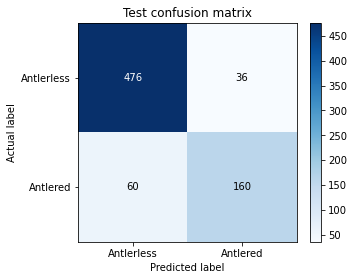


Reports and predictions saved to: X:\aanand37\Manuscript\Snapshot Wisconsin\data


In [14]:
# =============================================================================
# CELL 10 - Classification report on the held-out test set
# =============================================================================

# Select threshold using ONLY validation data.
threshold = 0.5

if CFG.tune_threshold:
    val_result = evaluate(model, make_loader(va, train=False))
    thresholds = np.linspace(0.01, 0.99, 99)

    scores = [
        f1_score(
            val_result["labels"],
            (val_result["probs"] > t).astype(int),
            labels=[0, 1],
            average="macro",
            zero_division=0,
        )
        for t in thresholds
    ]

    # If several thresholds tie, choose the one closest to 0.5.
    best_indices = np.flatnonzero(
        np.isclose(scores, np.max(scores), rtol=0, atol=1e-12)
    )
    best_idx = best_indices[
        np.argmin(np.abs(thresholds[best_indices] - 0.5))
    ]
    threshold = float(thresholds[best_idx])

    print(f"Selected threshold: {threshold:.2f}")
    print(f"Validation macro-F1: {scores[best_idx]:.4f}")

# Evaluate the test set once using the selected threshold.
test_result = evaluate(
    model,
    make_loader(te, train=False),
    threshold=threshold,
)

y_true = test_result["labels"]
y_pred = (test_result["probs"] > threshold).astype(int)

report_text = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=ANTLER_NAMES,
    digits=4,
    zero_division=0,
)

print(f"\nTest classification report | threshold = {threshold:.2f}\n")
print(report_text)
print(f"Test accuracy: {test_result['acc']:.4f}")
print(f"Test macro-F1: {test_result['f1']:.4f}")

# Save the report.
report_dict = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=ANTLER_NAMES,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report_dict).T
report_df.to_csv(
    os.path.join(CFG.out_dir, "antler_classification_report.csv"),
    index_label="metric",
)

with open(
    os.path.join(CFG.out_dir, "antler_classification_report.txt"),
    "w",
    encoding="utf-8",
) as f:
    f.write(f"Decision threshold: {threshold:.4f}\n\n")
    f.write(report_text)

# Save per-row test predictions in the same order as the test dataframe.
predictions = te.copy()
predictions["prob_antlered"] = test_result["probs"]
predictions["predicted_class"] = y_pred
predictions["predicted_label"] = [
    ANTLER_NAMES[int(v)] for v in y_pred
]
predictions["correct"] = y_true == y_pred
predictions["decision_threshold"] = threshold
predictions.to_csv(
    os.path.join(CFG.out_dir, CFG.pred_file),
    index=False,
)

# Display the confusion matrix.
cm = test_result["cm"]
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
fig.colorbar(im, ax=ax)

ax.set(
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=ANTLER_NAMES,
    yticklabels=ANTLER_NAMES,
    xlabel="Predicted label",
    ylabel="Actual label",
    title="Test confusion matrix",
)

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
        )

plt.tight_layout()
plt.show()

print(f"\nReports and predictions saved to: {CFG.out_dir}")

In [ ]:
## confusion metrics without thresholding

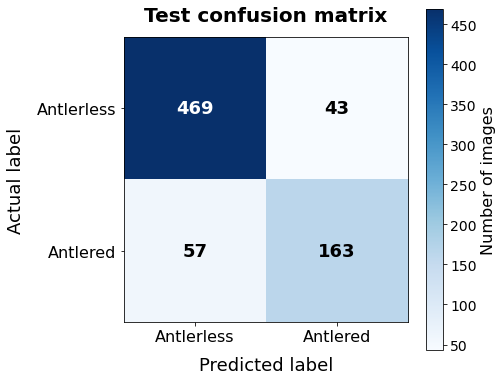

In [18]:
# =============================================================================
# CELL 10 - Held-out test report using argmax (no threshold tuning)
# =============================================================================

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

# Run inference directly so this cell does not depend on the
# threshold-based evaluate() function.
test_loader = make_loader(te, train=False)
model.eval()

device = next(model.parameters()).device
use_amp = bool(CFG.amp and device.type == "cuda")

all_labels = []
all_predictions = []
all_prob_antlered = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device, non_blocking=True)

        with torch.autocast(device.type, enabled=use_amp):
            logits = model(x)

        logits = logits.float()

        # Select whichever class has the highest model score.
        predicted_classes = logits.argmax(dim=1)

        # Retain probabilities for inspection, not class selection.
        prob_antlered = logits.softmax(dim=1)[:, 1]

        all_labels.append(y.detach().cpu().numpy())
        all_predictions.append(predicted_classes.cpu().numpy())
        all_prob_antlered.append(prob_antlered.cpu().numpy())

if not all_labels:
    raise ValueError("The test loader is empty.")

y_true = np.concatenate(all_labels).astype(int)
y_pred = np.concatenate(all_predictions).astype(int)
prob_antlered = np.concatenate(all_prob_antlered)

if len(y_true) != len(te):
    raise ValueError("Test predictions do not match the number of test rows.")

test_accuracy = accuracy_score(y_true, y_pred)
test_macro_f1 = f1_score(
    y_true,
    y_pred,
    labels=[0, 1],
    average="macro",
    zero_division=0,
)
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

report_text = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=ANTLER_NAMES,
    digits=4,
    zero_division=0,
)

print("\nTest classification report | decision rule: argmax\n")
print(report_text)
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test macro-F1: {test_macro_f1:.4f}")

# =============================================================================
# Save reports
# =============================================================================

os.makedirs(CFG.out_dir, exist_ok=True)

report_dict = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=ANTLER_NAMES,
    output_dict=True,
    zero_division=0,
)

pd.DataFrame(report_dict).T.to_csv(
    os.path.join(CFG.out_dir, "antler_classification_report.csv"),
    index_label="metric",
)

with open(
    os.path.join(CFG.out_dir, "antler_classification_report.txt"),
    "w",
    encoding="utf-8",
) as f:
    f.write("Decision rule: argmax\n\n")
    f.write(report_text)

# =============================================================================
# Save per-row predictions
# make_loader(te, train=False) preserves the test dataframe order.
# =============================================================================

predictions = te.copy()
predictions = predictions.drop(
    columns=["decision_threshold"],
    errors="ignore",
)
predictions["prob_antlered"] = prob_antlered
predictions["predicted_class"] = y_pred
predictions["predicted_label"] = [
    ANTLER_NAMES[int(v)] for v in y_pred
]
predictions["correct"] = y_true == y_pred
predictions["decision_rule"] = "argmax"

predictions.to_csv(
    os.path.join(CFG.out_dir, CFG.pred_file),
    index=False,
)

# =============================================================================
# Display confusion matrix
# =============================================================================

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
fig.colorbar(im, ax=ax)

ax.set(
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=ANTLER_NAMES,
    yticklabels=ANTLER_NAMES,
    xlabel="Predicted label",
    ylabel="Actual label",
    title="Test confusion matrix — argmax",
)

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
        )

plt.tight_layout()
plt.show()

print(f"\nReports and predictions saved to: {CFG.out_dir}")

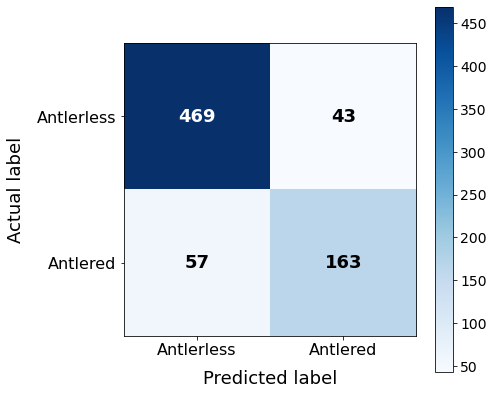

In [22]:
# =============================================================================
# Display confusion matrix with larger text
# =============================================================================

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(cm, cmap="Blues")

# Color bar
cbar = fig.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=14)


# Class labels
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(ANTLER_NAMES, fontsize=16)
ax.set_yticklabels(ANTLER_NAMES, fontsize=16)

# Axis labels and title
ax.set_xlabel("Predicted label", fontsize=18, labelpad=12)
ax.set_ylabel("Actual label", fontsize=18, labelpad=12)
ax.set_title(
    "",
    fontsize=20,
    fontweight="bold",
    pad=16,
)

# Numbers inside the matrix
for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=18,
            fontweight="bold",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
        )

ax.grid(False)
plt.tight_layout()
plt.show()